In [27]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [28]:
df = pd.read_csv("uber.csv")
df.head(10)

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
5,44470845,2011-02-12 02:27:09.0000006,4.9,2011-02-12 02:27:09 UTC,-73.969019,40.755910,-73.969019,40.755910,1
6,48725865,2014-10-12 07:04:00.0000002,24.5,2014-10-12 07:04:00 UTC,-73.961447,40.693965,-73.871195,40.774297,5
7,44195482,2012-12-11 13:52:00.00000029,2.5,2012-12-11 13:52:00 UTC,0.000000,0.000000,0.000000,0.000000,1
8,15822268,2012-02-17 09:32:00.00000043,9.7,2012-02-17 09:32:00 UTC,-73.975187,40.745767,-74.002720,40.743537,1
9,50611056,2012-03-29 19:06:00.000000273,12.5,2012-03-29 19:06:00 UTC,-74.001065,40.741787,-73.963040,40.775012,1


In [29]:
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
df=df[df.fare_amount > 0]
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], utc=True)
df["hour"] = df["pickup_datetime"].dt.hour

df.drop(["key", "pickup_datetime"], axis=1, inplace=True, errors="ignore")

In [30]:
Q1 , Q3 = df.fare_amount.quantile([0.25,0.75])
IQR= Q3-Q1
df = df[(df.fare_amount >= Q1 - 1.5*IQR) &
        (df.fare_amount <= Q3 + 1.5*IQR)]

In [31]:
df.head(10)

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17
5,44470845,4.9,-73.969019,40.755910,-73.969019,40.755910,1,2
7,44195482,2.5,0.000000,0.000000,0.000000,0.000000,1,13
8,15822268,9.7,-73.975187,40.745767,-74.002720,40.743537,1,9
9,50611056,12.5,-74.001065,40.741787,-73.963040,40.775012,1,19
10,2205147,6.5,-73.974388,40.746952,-73.988586,40.729805,1,17


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour
Unnamed: 0,1.0,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
fare_amount,-0.0,1.00,0.00,0.00,-0.00,0.00,0.01,-0.01
pickup_longitude,0.0,0.00,1.00,-0.81,0.84,-0.85,-0.00,0.00
pickup_latitude,-0.0,0.00,-0.81,1.00,-0.77,0.68,-0.00,-0.00
dropoff_longitude,0.0,-0.00,0.84,-0.77,1.00,-0.91,0.00,0.00
dropoff_latitude,-0.0,0.00,-0.85,0.68,-0.91,1.00,-0.00,-0.00
passenger_count,0.0,0.01,-0.00,-0.00,0.00,-0.00,1.00,0.01
hour,0.0,-0.01,0.00,-0.00,0.00,-0.00,0.01,1.00


NameError: name 'plt' is not defined

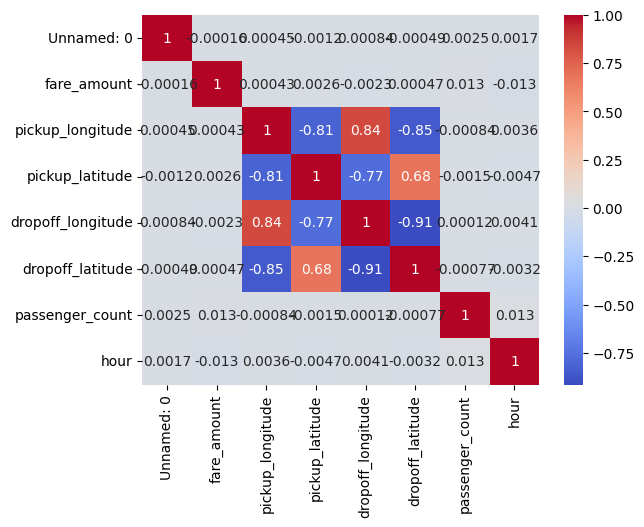

In [32]:
display(df.corr(numeric_only=True).round(2))
sns.heatmap(df.corr(numeric_only=True) ,annot=True, cmap="coolwarm" )
plt.show()

In [33]:
X= df.drop("fare_amount",axis=1)
y=df["fare_amount"]

X_train,X_test,y_train,y_test= train_test_split(X,y,train_size=0.2, random_state=42)
 

In [35]:
lr = LinearRegression().fit(X_train,y_train)
rf = RandomForestRegressor(n_estimators=10, random_state=42).fit(X_train, y_train)

In [37]:
for model in [lr,rf]:
    pred = model.predict(X_test)
    print("r2 score:", r2_score(y_test,pred))
    print("rsme", np.sqrt(mean_squared_error(y_test,pred)))

r2 score: -0.00023687400193472818
rsme 4.145007365268047
r2 score: 0.6634214220408099
rsme 2.4044575367602046
